# CSCI E-89: Problem Set 05, Problem 2

Schwartzberg, Paul

## Batch normalisation and augmentation for flower classification

We adapt the three-block `BasicCNN` in the supplied `1_Augmentation_CNN_Classify_flowers.ipynb`. Four controlled runs compare the original model with a model that adds `BatchNorm2d` immediately after each convolution, each trained with and without augmentation. No extra convolution or classifier layers are added here.

All runs use one stratified 70/15/15 flower split, the same initial convolution and linear weights, seed 42, 64 x 64 RGB images, batches of 64, Adam at 0.001, and 30 epochs. The course code sets 30 epochs, although its opening prose says 15. We follow the executable setting.

We select each checkpoint by validation loss, then evaluate it on every test image. The assignment uses the word *precision* for overall performance. We report both classification accuracy and macro precision, so the two meanings are clear. Accuracy is correct predictions divided by all images. For each class, precision is correct predictions of that class divided by all predictions of that class; macro precision averages those five values equally.

## 1. Shared data and evaluation functions

The definitions below also live in `hw5_common.py` for reuse by scripts. They are included here so the notebook does not depend on that local module. They download or reuse the original Flower Photos files, build and check the split, save the exact paths, open RGB photos, and calculate image-weighted loss and full-dataset metrics.

`run_epoch` trains only when supplied with an optimiser. Otherwise it uses evaluation mode and disables gradients. `evaluate_classifier` collects every test prediction and checks the image count. Caching stores original RGB photos before augmentation; each training visit still samples new random transformations.

In [1]:
"""Schwartzberg, Paul. Shared data and evaluation tools for CSCI E-89 HW5.

All flower problems reuse the same split. This module never trains a model on
validation or test images. Training is requested explicitly through run_epoch.
"""
from pathlib import Path
import json
import random
import shutil
import hashlib

import numpy as np
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.datasets.utils import download_and_extract_archive
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, precision_score

ROOT = Path.cwd()
SEED = 42
FLOWER_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

def seed_everything(seed=SEED):
    """Reset Python, NumPy and PyTorch random choices for a repeatable run."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def choose_device():
    """Prefer CUDA if present; this computer currently uses the CPU."""
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def write_json(path, data):
    """Write a readable UTF-8 record of settings or measured results."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

def cpu_state(model):
    """Copy weights and buffers: later updates cannot alter this checkpoint."""
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def prepare_flower_data(data_dir=ROOT / "data"):
    """Find/download Flower Photos and save a fixed stratified 70/15/15 split.

    A local copy from HW4 can supply the original downloaded files. Fresh clones
    download the archive if neither copy is present. Only the paths and labels,
    not resized images or augmentation, determine the split.
    """
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    flower_root = data_dir / "flower_photos"
    if not flower_root.exists():
        prior = ROOT.parents[2] / "Week4" / "Assignment" / "dec04c" / "data" / "flower_photos"
        if prior.exists():
            print("Copying the original Flower Photos files already downloaded for HW4.", flush=True)
            shutil.copytree(prior, flower_root)
        else:
            download_and_extract_archive(FLOWER_URL, download_root=str(data_dir))
    catalog = datasets.ImageFolder(flower_root)
    records = [(Path(path), int(label)) for path, label in catalog.samples]
    class_names = list(catalog.classes)
    assert class_names == ["daisy", "dandelion", "roses", "sunflowers", "tulips"]
    train, remaining = train_test_split(records, test_size=0.30, random_state=SEED,
                                        stratify=[label for _, label in records])
    validation, test = train_test_split(remaining, test_size=0.50, random_state=SEED,
                                        stratify=[label for _, label in remaining])
    splits = {"train": train, "validation": validation, "test": test}
    path_sets = [set(path for path, _ in rows) for rows in splits.values()]
    assert all(path_sets[i].isdisjoint(path_sets[j]) for i in range(3) for j in range(i+1,3))
    assert set.union(*path_sets) == {path for path, _ in records}
    manifest = {
        "author": "Schwartzberg, Paul", "seed": SEED, "dataset_url": FLOWER_URL,
        "class_names": class_names, "split_proportions": [0.70, 0.15, 0.15],
        "counts": {name: len(rows) for name, rows in splits.items()},
        "class_counts": {name: np.bincount([label for _, label in rows], minlength=5).tolist()
                         for name, rows in splits.items()},
        "splits": {name: [path.relative_to(flower_root).as_posix() for path, _ in rows]
                   for name, rows in splits.items()},
    }
    # A digest identifies this exact ordering and split in every saved experiment.
    manifest["split_sha256"] = hashlib.sha256(
        json.dumps(manifest["splits"], sort_keys=True).encode("utf-8")).hexdigest()
    manifest_path = ROOT / "outputs/shared/split_manifest.json"
    if manifest_path.exists():
        previous = json.loads(manifest_path.read_text(encoding="utf-8"))
        if previous["split_sha256"] != manifest["split_sha256"]:
            raise ValueError("The saved flower split differs from the current dataset. Preserve and review it before training.")
    write_json(manifest_path, manifest)
    return {"root": flower_root, "class_names": class_names, "records": splits, "manifest": manifest}

class PhotoDataset(Dataset):
    """Open each RGB photo and apply only this split's transform.

    Optional image caching stores original RGB pixels, before random training
    transforms. Augmentation is still sampled again for each visit.
    """
    def __init__(self, records, transform, cache_images=False):
        self.records = list(records)
        self.transform = transform
        self.cached = None
        if cache_images:
            self.cached = []
            for path, _ in self.records:
                with Image.open(path) as picture:
                    self.cached.append(picture.convert("RGB"))
    def __len__(self):
        return len(self.records)
    def __getitem__(self, index):
        path, label = self.records[index]
        if self.cached is None:
            with Image.open(path) as picture:
                image = self.transform(picture.convert("RGB"))
        else:
            image = self.transform(self.cached[index].copy())
        return image, label

def run_epoch(model, loader, device, optimizer=None):
    """Train when an optimizer is supplied; otherwise evaluate without gradients."""
    training = optimizer is not None
    model.train(training)
    loss_function = nn.CrossEntropyLoss()
    loss_sum, correct, count = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_function(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite cross-entropy loss.")
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += float(loss.detach()) * len(labels)
            correct += int((logits.argmax(1) == labels).sum())
            count += len(labels)
    assert count == len(loader.dataset), "The loader omitted or repeated dataset items."
    return {"loss": loss_sum / count, "accuracy": correct / count, "count": count}

def evaluate_classifier(model, loader, device, class_names):
    """Evaluate every supplied image; report accuracy and the literal precision metric."""
    model.eval()
    loss_function = nn.CrossEntropyLoss()
    actual, predicted, probabilities = [], [], []
    loss_sum = 0.0
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device))
            loss_sum += float(loss_function(logits, labels.to(device))) * len(labels)
            actual.extend(labels.tolist())
            predicted.extend(logits.argmax(1).cpu().tolist())
            probabilities.extend(logits.softmax(1).cpu().tolist())
    count = len(actual)
    assert count == len(loader.dataset), "Final evaluation must use the entire dataset."
    labels = list(range(len(class_names)))
    report = classification_report(actual, predicted, labels=labels, target_names=class_names,
                                   zero_division=0, output_dict=True)
    return {
        "count": count, "loss": loss_sum / count,
        "accuracy": float(accuracy_score(actual, predicted)),
        "macro_precision": float(precision_score(actual, predicted, labels=labels, average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(actual, predicted)),
        "report": report, "confusion_matrix": confusion_matrix(actual, predicted, labels=labels).tolist(),
        "true_labels": actual, "predicted_labels": predicted, "probabilities": probabilities,
    }


## 2. Environment and fixed settings

Use the `cscie89` kernel. These settings are fixed before any results are inspected. Limiting CPU threads reduces overhead and allows the separate VGG16 run to use the computer at the same time.

In [2]:
# Show the environment and use four CPU threads per training process.
import time
import sys
import torchvision
from torch.utils.data import DataLoader
from torchvision import transforms
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay

torch.set_num_threads(4)
seed_everything()
device = choose_device()
IMAGE_SIZE, BATCH_SIZE, EPOCHS, LEARNING_RATE = 64, 64, 30, 0.001
OUTPUT_DIR = ROOT / "outputs/problem2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__, "| device:", device)
print("Settings:", IMAGE_SIZE, "pixels; batch", BATCH_SIZE, "; epochs", EPOCHS, "; Adam learning rate", LEARNING_RATE)


Python: C:\Users\schwa\.conda\envs\cscie89\python.exe
PyTorch: 2.14.0+cpu | torchvision: 0.29.0+cpu | device: cpu
Settings: 64 pixels; batch 64 ; epochs 30 ; Adam learning rate 0.001


## 3. One split and two training transforms

The split is stratified, meaning it keeps roughly the same class proportions in each part. The saved manifest records exact paths and verifies that the three parts do not overlap.

The unaugmented condition resizes and converts to a tensor. The augmented condition also uses random left-right flips, rotations within 15 degrees, and mild brightness and contrast changes, as in the course notebook. Validation and testing use only fixed preprocessing. No normalisation other than 0-1 pixel scaling is introduced, so BatchNorm and augmentation remain the experimental changes.

In [3]:
# Prepare one split for every model, and show its class counts.
flower_data = prepare_flower_data()
flower_classes = flower_data["class_names"]
flower_records = flower_data["records"]
for name in ("train", "validation", "test"):
    counts = flower_data["manifest"]["class_counts"][name]
    print(name, len(flower_records[name]), "images:", dict(zip(flower_classes, counts)))

# Validation and test receive only the fixed resize and pixel scaling.
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor(),
])
augmented_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
])
val_dataset = PhotoDataset(flower_records["validation"], eval_transform, cache_images=True)
test_dataset = PhotoDataset(flower_records["test"], eval_transform, cache_images=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
                         generator=torch.Generator().manual_seed(SEED))


train 2569 images: {'daisy': 443, 'dandelion': 629, 'roses': 449, 'sunflowers': 489, 'tulips': 559}
validation 550 images: {'daisy': 95, 'dandelion': 134, 'roses': 96, 'sunflowers': 105, 'tulips': 120}
test 551 images: {'daisy': 95, 'dandelion': 135, 'roses': 96, 'sunflowers': 105, 'tulips': 120}


## 4. Inspect training augmentation

One training photograph is shown with four independently sampled views. Its class label remains the same. The training functions reset the random seeds after this preview, so drawing the preview does not change the experiments' starting random state.

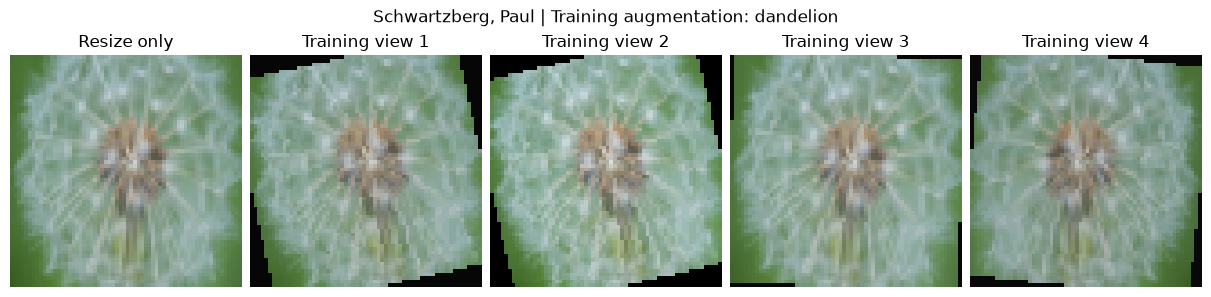

In [4]:
# Show four random training views of one image, with the same label.
preview_path, preview_label = flower_records["train"][0]
with Image.open(preview_path) as picture:
    picture = picture.convert("RGB")
    fig, axes = plt.subplots(1, 5, figsize=(12, 3), layout="constrained")
    for index, ax in enumerate(axes):
        shown = (eval_transform if index == 0 else augmented_transform)(picture)
        ax.imshow(shown.permute(1, 2, 0))
        ax.set_title("Resize only" if index == 0 else f"Training view {index}")
        ax.axis("off")
fig.suptitle(f"Schwartzberg, Paul | Training augmentation: {flower_classes[preview_label]}")
fig.savefig(OUTPUT_DIR / "augmentation_examples.png", dpi=120)
plt.show()
# Experiments below reset all seeds after this preview.


## 5. Define the original and batch-normalised models

Both variants have convolution widths 16, 32 and 64, followed by a linear head from 4,096 values to 64 and then five class scores. The added layer order is `Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d`.

During training, BatchNorm uses batch statistics and updates running estimates. During evaluation, it uses those saved running estimates. Its learned scale and offset are additional parameters. We keep the original convolution biases to change only the requested layers.

`copy_shared_start` copies the same convolution and linear values into every model. A digest checks that these starting values match. The BatchNorm scale and offset retain their usual initial values of one and zero.

In [5]:
"""Schwartzberg, Paul. BasicCNN variants for CSCI E-89 HW5 Problem 2."""
import hashlib
import torch
from torch import nn

class BasicCNN(nn.Module):
    """The three-block course model, with optional BatchNorm after each Conv2d."""
    def __init__(self, num_classes=5, batch_norm=False, image_size=64):
        super().__init__()
        layers = []
        in_channels = 3
        for out_channels in (16, 32, 64):
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))  # Before ReLU, after every convolution.
            layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
            in_channels = out_channels
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * (image_size // 8) ** 2, 64),
            nn.ReLU(), nn.Linear(64, num_classes),
        )
    def forward(self, images):
        return self.classifier(self.features(images))

def shared_layers(model):
    """Return the convolutions and linear layers, in the same order in both variants."""
    return [layer for layer in model.modules() if isinstance(layer, (nn.Conv2d, nn.Linear))]

def copy_shared_start(model, reference):
    """Give every experiment exactly the same starting convolution and linear weights."""
    for target, source in zip(shared_layers(model), shared_layers(reference), strict=True):
        target.load_state_dict(source.state_dict(), strict=True)

def shared_weight_digest(model):
    """Identify the shared initial weights, excluding the added BatchNorm parameters."""
    digest = hashlib.sha256()
    for layer in shared_layers(model):
        for value in layer.state_dict().values():
            digest.update(value.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


In [6]:
# The only two experimental changes are BatchNorm and training augmentation.
EXPERIMENTS = [
    {"name": "original_no_augmentation", "batch_norm": False, "augmentation": False},
    {"name": "batchnorm_no_augmentation", "batch_norm": True, "augmentation": False},
    {"name": "original_with_augmentation", "batch_norm": False, "augmentation": True},
    {"name": "batchnorm_with_augmentation", "batch_norm": True, "augmentation": True},
]
seed_everything()
reference_model = BasicCNN(len(flower_classes))
INITIAL_DIGEST = shared_weight_digest(reference_model)
example_model = BasicCNN(len(flower_classes), batch_norm=True)
copy_shared_start(example_model, reference_model)
assert shared_weight_digest(example_model) == INITIAL_DIGEST
assert sum(isinstance(layer, nn.BatchNorm2d) for layer in example_model.modules()) == 3
for index, layer in enumerate(example_model.features):
    if isinstance(layer, nn.Conv2d):
        assert isinstance(example_model.features[index + 1], nn.BatchNorm2d)
print(example_model)
print("Shared initial convolution/linear digest:", INITIAL_DIGEST)


BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=64, bias=True)
  

## 6. Train four runs and save selected checkpoints

The function resets seeds and the shuffled-loader generator for each condition. Batch order and common starting weights match across runs; augmented views add their own random variation. Cross-entropy compares five raw class scores with integer labels.

Every epoch includes a training pass and a separate validation pass. Whenever validation loss improves, we copy the complete state, including BatchNorm running statistics. We restore that state after 30 epochs and verify that a saved-and-reloaded model returns the same scores. Test images are not read during this selection.

Only selected progress lines are printed here. The JSON histories contain all 30 epochs, and the plots below show them all.

In [7]:
def train_basic_experiment(config):
    """Train one condition, using validation loss to select its checkpoint."""
    seed_everything()
    model = BasicCNN(len(flower_classes), batch_norm=config["batch_norm"]).to(device)
    copy_shared_start(model, reference_model)
    assert shared_weight_digest(model) == INITIAL_DIGEST
    transform = augmented_transform if config["augmentation"] else eval_transform
    dataset = PhotoDataset(flower_records["train"], transform, cache_images=True)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
                        generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    # Reset stochastic transforms after construction; each run has the same batch order.
    seed_everything()
    history = {key: [] for key in ("train_loss", "val_loss", "train_accuracy", "val_accuracy")}
    best_loss, best_epoch, best_state = float("inf"), None, None
    start = time.perf_counter()
    print("Training:", config["name"], flush=True)
    for epoch in range(1, EPOCHS + 1):
        train = run_epoch(model, loader, device, optimizer)
        validation = run_epoch(model, val_loader, device)
        history["train_loss"].append(train["loss"])
        history["train_accuracy"].append(train["accuracy"])
        history["val_loss"].append(validation["loss"])
        history["val_accuracy"].append(validation["accuracy"])
        if validation["loss"] < best_loss:
            best_loss, best_epoch = validation["loss"], epoch
            best_state = cpu_state(model)
        # All epochs go to JSON; a short output keeps the submitted notebook readable.
        if epoch == 1 or epoch % 10 == 0:
            print(f"  Epoch {epoch:02d}/{EPOCHS}: train loss {train['loss']:.4f}, acc {train['accuracy']:.2%}; "
                  f"validation loss {validation['loss']:.4f}, acc {validation['accuracy']:.2%}", flush=True)
    model.load_state_dict(best_state, strict=True)
    selected = run_epoch(model, val_loader, device)
    checkpoint = {
        "author": "Schwartzberg, Paul", "state_dict": cpu_state(model), "config": config,
        "class_names": flower_classes, "image_size": IMAGE_SIZE, "best_epoch": best_epoch,
        "seed": SEED, "split_sha256": flower_data["manifest"]["split_sha256"],
        "initial_shared_sha256": INITIAL_DIGEST, "selection_rule": "minimum validation cross-entropy loss",
    }
    checkpoint_path = OUTPUT_DIR / (config["name"] + ".pth")
    torch.save(checkpoint, checkpoint_path)
    # Confirm the saved file restores the selected model's scores, including BN buffers.
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    reloaded = BasicCNN(len(flower_classes), batch_norm=config["batch_norm"]).to(device)
    reloaded.load_state_dict(saved["state_dict"], strict=True)
    model.eval(); reloaded.eval()
    sample = val_dataset[0][0].unsqueeze(0).to(device)
    with torch.no_grad():
        torch.testing.assert_close(model(sample), reloaded(sample), rtol=0, atol=0)
    result = {
        "author": "Schwartzberg, Paul", "config": config, "seed": SEED,
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "initial_shared_sha256": INITIAL_DIGEST, "split_sha256": saved["split_sha256"],
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": best_epoch, "selected_validation": selected, "history": history,
        "training_seconds": time.perf_counter() - start, "reload_verified": True,
    }
    write_json(OUTPUT_DIR / (config["name"] + "_metrics.json"), result)
    print(f"  Restored epoch {best_epoch}; validation loss {selected['loss']:.4f}; reload verified.", flush=True)
    return result

# Train and select all four checkpoints before examining any test results.
p2_results = [train_basic_experiment(config) for config in EXPERIMENTS]


Training: original_no_augmentation


  Epoch 01/30: train loss 1.4530, acc 33.36%; validation loss 1.2773, acc 45.64%


  Epoch 10/30: train loss 0.8207, acc 67.11%; validation loss 0.9411, acc 63.09%


  Epoch 20/30: train loss 0.5518, acc 78.67%; validation loss 1.0060, acc 64.91%


  Epoch 30/30: train loss 0.2431, acc 91.44%; validation loss 1.2124, acc 67.45%


...

  Epoch 01/30: train loss 1.3198, acc 47.49%; validation loss 1.3483, acc 40.18%


  Epoch 10/30: train loss 0.6715, acc 74.15%; validation loss 0.7665, acc 71.64%


  Epoch 20/30: train loss 0.4664, acc 82.41%; validation loss 0.7371, acc 71.27%


  Epoch 30/30: train loss 0.3838, acc 86.26%; validation loss 0.7824, acc 73.45%


  Restored epoch 23; validation loss 0.6909; reload verified.


## 7. Compare complete test-set results

All four checkpoints have now been selected. This cell uses all 551 test images for each model, with fixed preprocessing, evaluation mode and no gradient calculation. It saves accuracy, macro precision, balanced accuracy, per-class precision/recall/F1, loss and each image's prediction. No test score is used to change an experiment or checkpoint.

In [8]:
# Evaluate every selected checkpoint on the same complete test set.
for result in p2_results:
    config = result["config"]
    checkpoint_path = OUTPUT_DIR / (config["name"] + ".pth")
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = BasicCNN(len(flower_classes), batch_norm=config["batch_norm"]).to(device)
    model.load_state_dict(checkpoint["state_dict"], strict=True)
    test = evaluate_classifier(model, test_loader, device, flower_classes)
    assert test["count"] == 551 == flower_data["manifest"]["counts"]["test"]
    result["test"] = test
    write_json(OUTPUT_DIR / (config["name"] + "_metrics.json"), result)
    print(config["name"], f"test accuracy {test['accuracy']:.2%}; macro precision {test['macro_precision']:.2%}; "
          f"loss {test['loss']:.4f}; images {test['count']}")
write_json(OUTPUT_DIR / "comparison.json", {"author": "Schwartzberg, Paul", "experiments": p2_results})

# Accuracy is the fraction correct; macro precision gives each class equal weight.
rows = ["| Condition | Selected epoch | Validation loss | Test accuracy | Test macro precision |",
        "|---|---:|---:|---:|---:|"]
for result in p2_results:
    rows.append(f"| {result['config']['name']} | {result['best_epoch']} | {result['selected_validation']['loss']:.4f} "
                f"| {result['test']['accuracy']:.2%} | {result['test']['macro_precision']:.2%} |")
display(Markdown("\n".join(rows)))


original_no_augmentation test accuracy 64.61%; macro precision 64.35%; loss 0.8797; images 551


batchnorm_no_augmentation test accuracy 70.96%; macro precision 70.98%; loss 0.8040; images 551


original_with_augmentation test accuracy 68.60%; macro precision 68.99%; loss 0.8101; images 551


batchnorm_with_augmentation test accuracy 74.77%; macro precision 74.38%; loss 0.7301; images 551


| Condition | Selected epoch | Validation loss | Test accuracy | Test macro precision |
|---|---:|---:|---:|---:|
| original_no_augmentation | 11 | 0.9146 | 64.61% | 64.35% |
| batchnorm_no_augmentation | 9 | 0.7678 | 70.96% | 70.98% |
| original_with_augmentation | 24 | 0.8238 | 68.60% | 68.99% |
| batchnorm_with_augmentation | 23 | 0.6909 | 74.77% | 74.38% |

## 8. Learning curves and confusion matrices

The training and validation histories show whether better training fit carries over to held-out images. The dashed line marks the selected checkpoint. A gap or rising validation loss can indicate overfitting; BatchNorm and augmentation do not guarantee that it disappears. Each confusion matrix includes the same full test set.

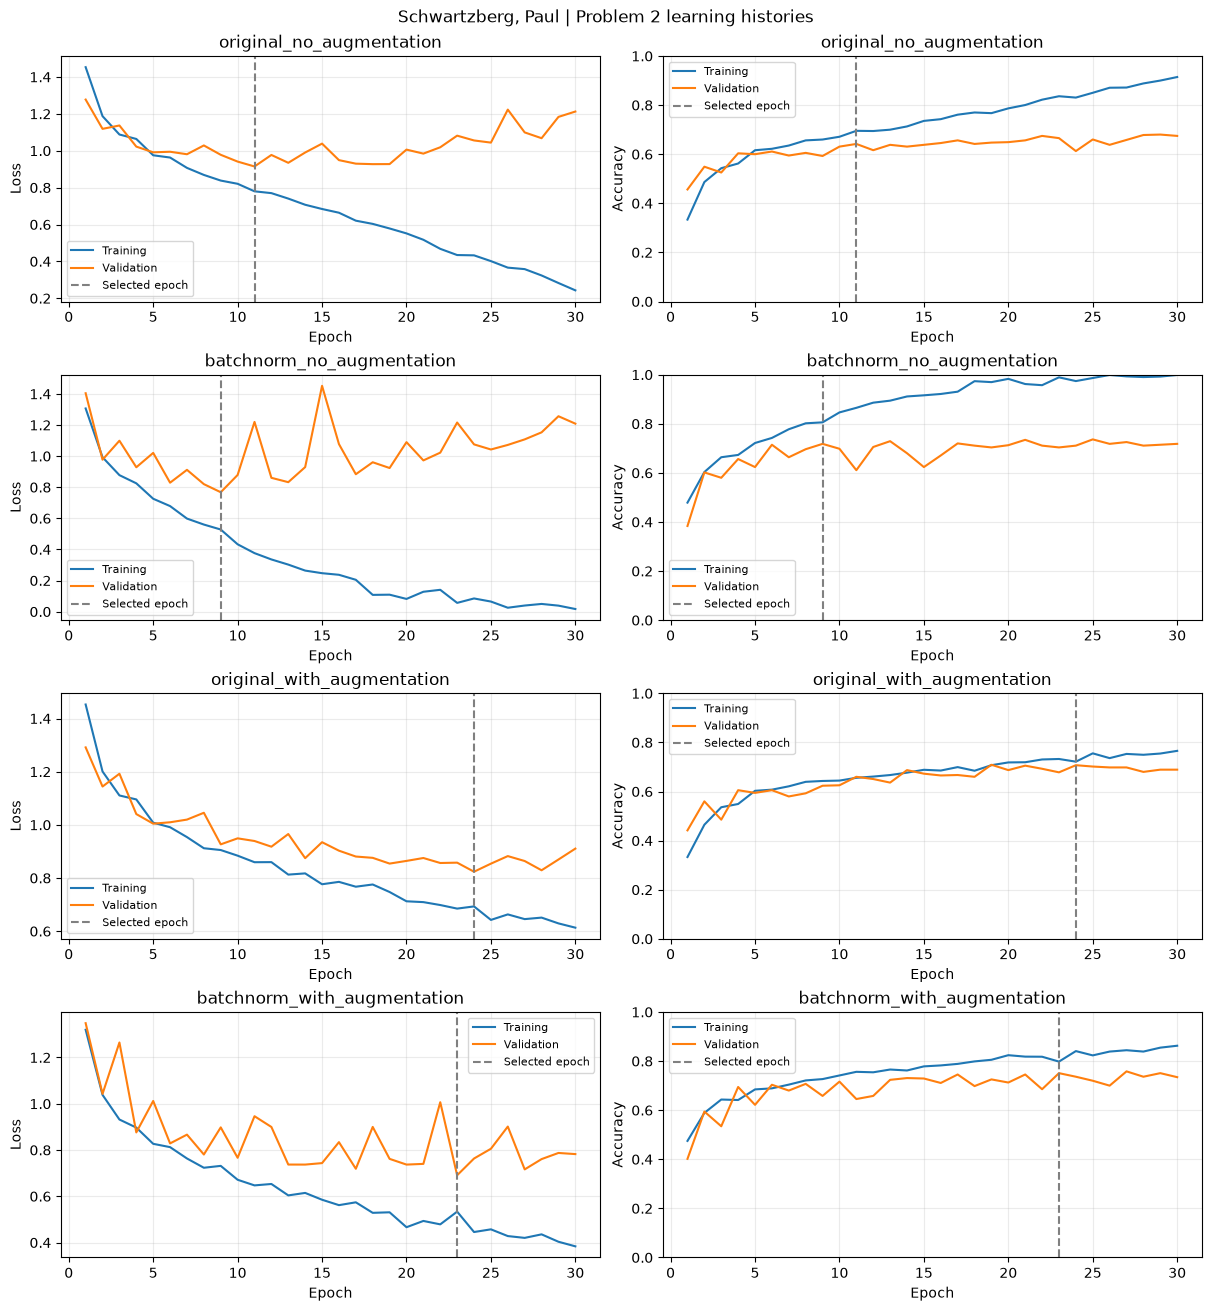

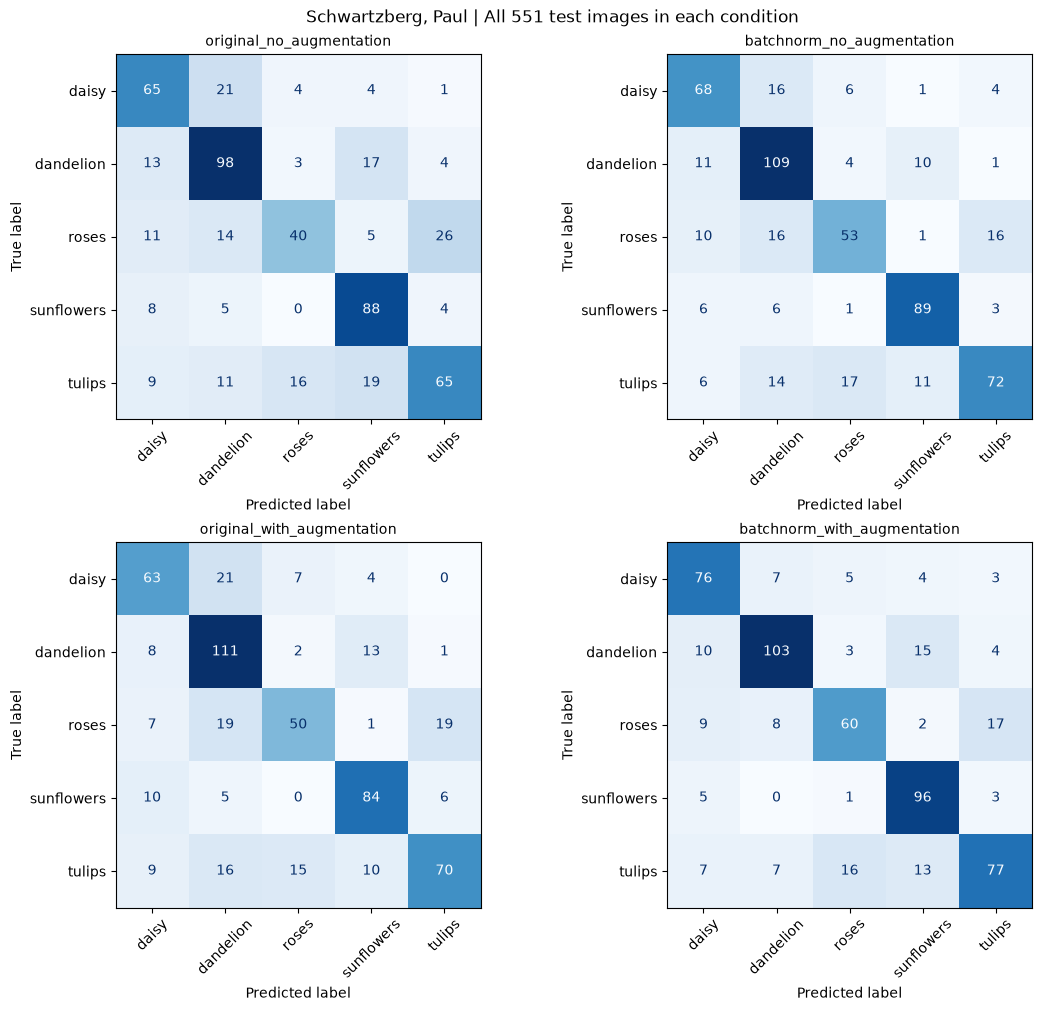

In [9]:
# Show every run's learning history and selected validation checkpoint.
fig, axes = plt.subplots(4, 2, figsize=(12, 13), layout="constrained")
for row, result in enumerate(p2_results):
    epochs = np.arange(1, len(result["history"]["train_loss"]) + 1)
    for col, metric in enumerate(("loss", "accuracy")):
        ax = axes[row, col]
        ax.plot(epochs, result["history"]["train_" + metric], label="Training")
        ax.plot(epochs, result["history"]["val_" + metric], label="Validation")
        ax.axvline(result["best_epoch"], color="grey", linestyle="--", label="Selected epoch")
        ax.set(title=result["config"]["name"], xlabel="Epoch", ylabel=metric.capitalize())
        ax.grid(alpha=0.25); ax.legend(fontsize=8)
        if metric == "accuracy": ax.set_ylim(0, 1)
fig.suptitle("Schwartzberg, Paul | Problem 2 learning histories")
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=120)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 10), layout="constrained")
for ax, result in zip(axes.flat, p2_results):
    ConfusionMatrixDisplay(np.array(result["test"]["confusion_matrix"]), display_labels=flower_classes).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(result["config"]["name"], fontsize=10)
fig.suptitle("Schwartzberg, Paul | All 551 test images in each condition")
fig.savefig(OUTPUT_DIR / "test_confusion_matrices.png", dpi=120)
plt.show()


## 9. Interpretation

| Condition | Selected epoch | Validation loss | Test correct / 551 | Test accuracy | Test macro precision |
|---|---:|---:|---:|---:|---:|
| Original, no augmentation | 11 | 0.9146 | 356 / 551 | 64.61% | 64.35% |
| BatchNorm, no augmentation | 9 | 0.7678 | 391 / 551 | 70.96% | 70.98% |
| Original, with augmentation | 24 | 0.8238 | 378 / 551 | 68.60% | 68.99% |
| BatchNorm, with augmentation | 23 | 0.6909 | 412 / 551 | 74.77% | 74.38% |

Adding BatchNorm increased test accuracy by 6.35 percentage points without augmentation and 6.17 points with augmentation. Adding augmentation increased accuracy by 3.99 points in the original model and 3.81 points in the BatchNorm model. The combined condition had the highest test accuracy and macro precision in these four fixed runs. Its test accuracy exceeded the original unaugmented model by 10.16 points.

**Training fit and overfitting.** Without augmentation, the original model reached 91.44% training accuracy at epoch 30, while the BatchNorm model reached 99.88%. Their final validation losses were both about 1.21, higher than their selected losses of 0.9146 and 0.7678. We therefore restored epochs 11 and 9. BatchNorm improved the selected held-out result, but did not prevent later overfitting.

Augmentation reduced the training/validation gap in the learning curves and moved the selected checkpoints later, to epochs 24 and 23. The combined condition ended with 86.26% training accuracy and 73.45% validation accuracy. Its lowest validation loss was 0.6909 at epoch 23; the final loss rose to 0.7824. We restored epoch 23 rather than the final weights. Training accuracy here is measured during training on the condition's current views; augmented training views are harder than the fixed validation images.

**Remaining errors.** In the combined condition, sunflowers had the highest test recall, 91.43%; roses had the lowest, 62.50%. Seventeen roses were predicted as tulips. Improvements were not uniform across classes: dandelion recall was 76.30% in the combined condition, compared with 80.74% for BatchNorm alone. The confusion matrices show those trade-offs.

These experiments use one seed, one split and one 30-epoch budget. We have not measured variation across repeated seeds. All four conditions were fixed before test evaluation; no test result changed an experiment or checkpoint. The complete test set, rather than a small gallery, supplies every reported test metric.

**Problem 2 is complete.** All four runs trained, selected checkpoints by validation loss, passed saved-weight reload checks, and evaluated every one of the 551 test images. Exact starting-weight and split digests, full histories, per-class reports, predictions and plots are saved in `outputs/problem2/`.
